# Experiment 192 · Replay timing and evaluation phase

**Complete** · Replay timing results saved · ETA 0h 00m 00s

The shared first A phase initializes each paired rollout. Replay starts at the first switch. The 25% fixed arm, 0%→50%, 50%→0%, and a seeded random ordering of 0% and 50% each spend 128 replay updates per 512 arrivals. The frontloaded arm is the periodic schedule shifted by 256 arrivals. Shifted readouts also score every policy at +256 within each pair, with its fixed comparator at the same arrivals. Each optimizer step uses one image.

The objective is current-bank MSE plus previous-bank forgetting above 0.005. Full-stream time averages include every 256-arrival readout after the first switch. Intervals are paired 95% Student t intervals over seed means after averaging within each seed over masks and the applicable times. Positive gains favor the listed policy.

Rollouts saved or reused · 48. Persistence sites · 72. Controller-origin sites · 0.

## Experiment 191 · Paired full-policy effects

| Policy | Reference | Objective gain [95% CI] | Seeds |
| --- | --- | --- | --- |
 | shift rule | 25% | -0.00429 [-0.00775, -0.00083] | 3 | 
 | shift rule | 50% | -0.02457 [-0.03048, -0.01867] | 3 | 
 | learned | 25% | -0.02762 [-0.04193, -0.01332] | 3 | 
 | learned | 50% | -0.04791 [-0.05900, -0.03682] | 3 | 
 | Fixed 50% | 25% | +0.02292 [+0.02108, +0.02476] | 6 | 

The 50% versus 25% row matches optimizer steps and varies the number of replay images. The adaptive versus 25% rows match both.

## A · Complete rollouts

| Policy | Readout grid | Pairs | Objective gain [95% CI] | Forgetting reduction | Adaptation gain |
| --- | --- | --- | --- | --- | --- |
 | backloaded | pair end | 12 | +0.01531 [+0.01206, +0.01856] | -0.00166 | +0.01148 | 
 | backloaded | shifted readout | 12 | -0.06389 [-0.07027, -0.05751] | -0.06774 | -0.02467 | 
 | backloaded | time average | 12 | -0.02429 [-0.02869, -0.01989] | -0.03470 | -0.00659 | 
 | frontloaded | pair end | 12 | -0.03416 [-0.04025, -0.02807] | -0.02601 | +0.00428 | 
 | frontloaded | shifted readout | 12 | +0.02155 [+0.01909, +0.02401] | +0.02152 | +0.04266 | 
 | frontloaded | time average | 12 | -0.00631 [-0.00949, -0.00313] | -0.00224 | +0.02347 | 
 | random balanced | pair end | 12 | -0.01275 [-0.01811, -0.00739] | -0.01543 | +0.00183 | 
 | random balanced | shifted readout | 12 | -0.02306 [-0.03156, -0.01457] | -0.03008 | +0.00394 | 
 | random balanced | time average | 12 | -0.01791 [-0.01995, -0.01587] | -0.02276 | +0.00289 | 

## B · Persistence after returning to fixed replay

Both branches use 25% replay after +512. At +256 the branches have spent different parts of their shared budget.

| Context | Arrivals | Sites | Objective gain [95% CI] | Forgetting reduction | Adaptation gain |
| --- | --- | --- | --- | --- | --- |
 | all | 256 | 72 | -0.06105 [-0.06771, -0.05439] | -0.06513 | -0.02417 | 
 | all | 512 | 72 | +0.01949 [+0.01119, +0.02778] | +0.01123 | +0.01672 | 
 | all | 768 | 72 | -0.00095 [-0.00307, +0.00117] | -0.00198 | +0.00032 | 
 | all | 1024 | 72 | -0.00084 [-0.00209, +0.00040] | -0.00069 | -0.00082 | 
 | switch | 256 | 36 | -0.08656 [-0.10490, -0.06823] | -0.09371 | -0.02658 | 
 | switch | 512 | 36 | +0.02075 [+0.01078, +0.03072] | +0.01579 | +0.01777 | 
 | switch | 768 | 36 | -0.00324 [-0.00956, +0.00307] | -0.00448 | -0.00055 | 
 | switch | 1024 | 36 | -0.00044 [-0.00293, +0.00206] | -0.00199 | -0.00020 | 
 | stable | 256 | 36 | -0.03553 [-0.04578, -0.02529] | -0.03654 | -0.02175 | 
 | stable | 512 | 36 | +0.01822 [+0.01060, +0.02584] | +0.00668 | +0.01568 | 
 | stable | 768 | 36 | +0.00134 [-0.00278, +0.00547] | +0.00051 | +0.00119 | 
 | stable | 1024 | 36 | -0.00125 [-0.00309, +0.00060] | +0.00061 | -0.00145 | 

Largest readout difference from matched Experiment 191 sites is 0 MSE.

**Phase C decision** · stop after Phase B. The gate requires positive backloaded time-averaged gain in the pooled mean and at least four of six seeds, plus a nonpositive Experiment 191 learned-policy gain against fixed 25%.



In [ ]:
# Run this cell to watch the background worker. Interrupt it to stop watching.
from IPython.display import Image, Markdown, clear_output, display
from pathlib import Path
import base64, json, time

run = Path('C:\\CAFL-E\\analysis\\2026-11-09-one-step-mpc\\o3-replay-endpoint')
while True:
    try:
        status = json.loads((run / 'status.json').read_text(encoding='utf-8'))
        cells = json.loads((run / 'progress.ipynb').read_text(encoding='utf-8'))['cells']
    except (FileNotFoundError, PermissionError):
        time.sleep(1)
        continue
    clear_output(wait=True)
    for cell in cells:
        if cell['cell_type'] == 'markdown':
            display(Markdown(''.join(cell['source'])))
        for output in cell.get('outputs', []):
            if png := output.get('data', {}).get('image/png'):
                display(Image(data=base64.b64decode(png)))
    if status['state'] in ('complete', 'stopped', 'failed'):
        break
    time.sleep(10)


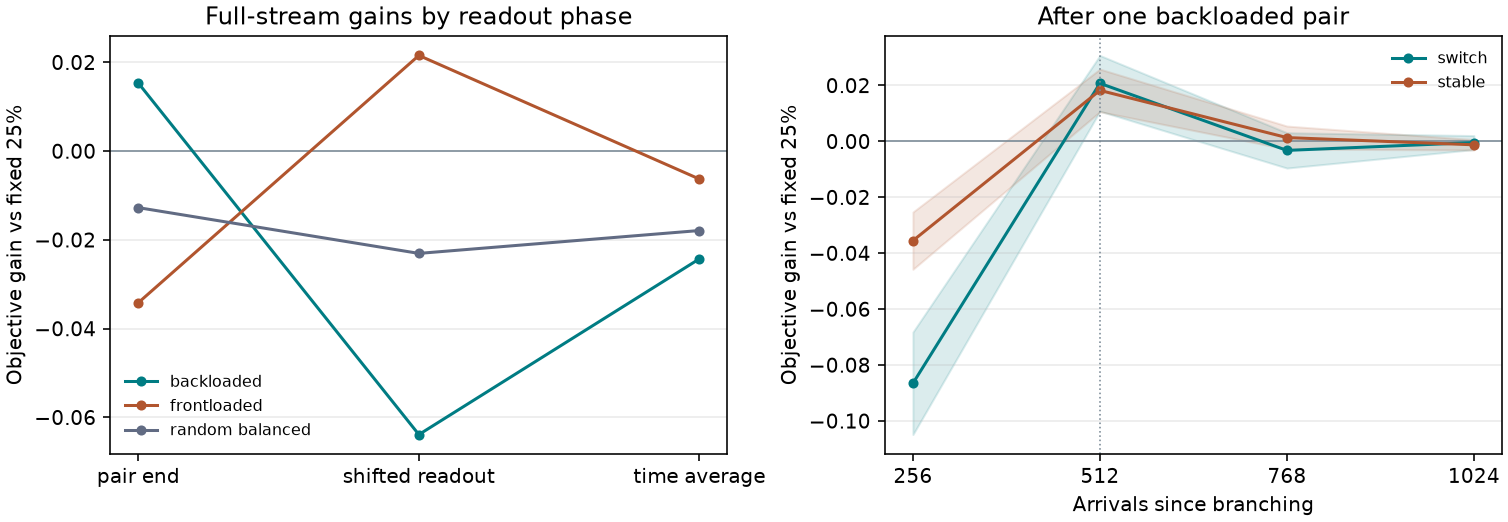